# Analyse Big Data des accidents de la route avec PySpark

## 1. Introduction

Cette étude reprend l'article de Rakesh Nain, *Big data Analysis of Road Crash Data using PySpark*. Elle analyse les accidents de la route en Australie-Méridionale entre 2012 et 2019 (données du DPTI) avec les trois structures de Spark : les RDD, les DataFrames et Spark SQL.

Deux jeux de données sont utilisés :
- crash_data : une ligne par accident ;
- units_data : une ligne par véhicule impliqué.

Ils sont reliés par la colonne REPORT_ID.

*Le jour exact de l'accident n'est pas publié (donnée sensible) : la date est donnée sous la forme Année-Mois-Jour de la semaine.*

Deux améliorations ont été apportées au code d'origine :
1. la lecture des lignes CSV avec le module csv, car split(',') découpe mal les champs qui contiennent une virgule ;
2. une comparaison des trois interfaces sur la même requête, avec vérification des résultats et mesure des temps.

## 2. Configuration de PySpark

On travaille ici en calcul parallèle (sur les cœurs d'une seule machine) et non en calcul distribué (sur plusieurs machines). Le principe est le même dans les deux cas.

In [2]:
from pyspark import SparkConf
from pyspark import SparkContext
from pyspark.sql import SparkSession
from pyspark.sql.functions import udf
from pyspark.sql.types import IntegerType
from pyspark.sql.types import LongType
from pyspark.sql.types import FloatType
from pyspark.rdd import RDD
from pyspark.sql.types import StringType
from pyspark.sql.functions import col
import pyspark.sql.functions as F
import csv
from datetime import datetime
from functools import reduce
import pandas as pd
import matplotlib.pyplot as plt
import time

In [5]:
import os
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"
master = "local[*]"
app_name = "Big data Analysis of Road Crash Data"
spark_conf = SparkConf().setMaster(master).setAppName(app_name)

In [6]:

spark = SparkSession.builder.config(conf=spark_conf).getOrCreate()
sc = spark.sparkContext
sc.setLogLevel('ERROR')

Un RDD (*Resilient Distributed Dataset*) est une collection d'objets immuable, découpée en partitions traitées en parallèle. On le crée avec :
- parallelize() : à partir d'une collection Python (liste, tuple…) ;
- textFile() : à partir d'un fichier texte, chaque ligne devenant un élément.

In [7]:
data_list = [i for i in range(10)]
rdd = sc.parallelize(data_list)
print('Default partitions: ', rdd.getNumPartitions())
rdd = sc.parallelize(data_list, 5)
print('Manual partitions: ', rdd.getNumPartitions())
rdd.collect()

Default partitions:  16
Manual partitions:  5


[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

In [8]:
units_rdd = sc.textFile('./units_data/*.csv')
crash_rdd = sc.textFile('./crash_data/*.csv')

In [12]:
units_header = units_rdd.first()
units_rdd = units_rdd.filter(lambda row: row != units_header)
print("Total count of units_rdd: ", units_rdd.count())
print(units_rdd.take(10))

Total count of units_rdd:  272591
['"2012-1-21/08/2019","01",0,,"Pedal Cycle",,"South West","Male","035",,,,,"Straight Ahead","001","5074",,', '"2012-1-21/08/2019","02",0,"SA","Motor Cars - Sedan","2009","North West","Female","050","SA","C ","Full","Unknown","Leaving Private Driveway","001","5089",,', '"2012-2-21/08/2019","01",0,"SA","Motor Cars - Sedan","1999","West","Male","027","SA",,"Provisional 1 ","Not Towing","Straight Ahead","002","5008",,', '"2012-2-21/08/2019","02",0,"SA","Motor Cars - Sedan","1993","West",,,,,,"Not Towing","Parked","000",,,', '"2012-3-21/08/2019","01",0,"SA","Motor Cars - Sedan","XXXX","North East","Male","050","SA",,"Full","Trailer","Straight Ahead","006","5107",,', '"2012-3-21/08/2019","02",0,"SA","Motor Cars - Sedan","2006","North East","Male","044","SA",,"Full","Not Towing","Straight Ahead","003","5092",,', '"2012-3-21/08/2019","03",0,,"Other Inanimate Object",,,,,,,,,,,,,', '"2012-4-21/08/2019","01",0,"SA","Station Wagon","2009","South West","Female","0

In [13]:
crash_header = crash_rdd.first()
crash_rdd = crash_rdd.filter(lambda row: row != crash_header)
print("Total count of crash_rdd: ", crash_rdd.count())
print(crash_rdd.take(10))

Total count of crash_rdd:  127672
['"2012-1-21/08/2019","2 Metropolitan","STEPNEY","5069","CC OF NORWOOD,PAYNEHAM & ST PETERS",2,0,0,0,0,2012,"January","Sunday","04:30 pm","060","Not Divided","Straight road","Level","Driveway or Entrance","Sealed","Dry","Not Raining","Daylight","Right Angle","02","Driver Rider","1: PDO","No Control","","",1330659.71,1671795.87,"13306601671796"', '"2012-2-21/08/2019","2 Metropolitan","PARKSIDE","5063","CITY OF UNLEY",2,0,0,0,0,2012,"January","Sunday","09:10 am","040","Not Divided","Straight road","Level","Not Applicable","Sealed","Dry","Not Raining","Daylight","Hit Parked Vehicle","01","Driver Rider","1: PDO","No Control","","",1329400.16,1668462.66,"13294001668463"', '"2012-3-21/08/2019","2 Metropolitan","SELLICKS BEACH","5174","CITY OF ONKAPARINGA",3,0,0,0,0,2012,"January","Wednesday","11:30 am","100","Not Divided","Straight road","Slope","Not Applicable","Sealed","Dry","Not Raining","Daylight","Other","01","Driver Rider","1: PDO","No Control","","",1

Par défaut, Spark découpe les données en partitions de taille à peu près égale.

In [14]:
print("Units Data:")
print(f"Total partitions: {units_rdd.getNumPartitions()}")
print("Crash Data:")
print(f"Total partitions: {crash_rdd.getNumPartitions()}")

Units Data:
Total partitions: 8
Crash Data:
Total partitions: 8


On peut aussi définir un partitionnement personnalisé. On place les véhicules immatriculés en Australie-Méridionale (SA) dans une partition, et tous les autres dans une seconde. On crée d'abord un RDD clé/valeur avec l'État d'immatriculation (colonne 3) comme clé.

In [19]:
def parseRecord(line):
    lines = line.split(',')
    array_line = []
    for value in lines:
        array_line.append(str(value).replace('"', ''))
    return (array_line[3], [x for i, x in enumerate(array_line) if i != 3])

units_state_rdd = units_rdd.map(parseRecord)

In [17]:
def hash_SA(key):
    if key == 'SA':
        return 0
    else:
        return 1

SA_partitioned_rdd = units_state_rdd.partitionBy(2, hash_SA)

In [18]:
def print_partitions(data):
    if isinstance(data, RDD):
        numPartitions = data.getNumPartitions()
        partitions = data.glom().collect()
    else:
        numPartitions = data.rdd.getNumPartitions()
        partitions = data.rdd.glom().collect()

    print(f"NUMBER OF PARTITIONS: {numPartitions}")
    for index, partition in enumerate(partitions):
        if len(partition) > 0:
            print(f"Partition {index}: {len(partition)} records")

print_partitions(SA_partitioned_rdd)

NUMBER OF PARTITIONS: 2
Partition 0: 218366 records
Partition 1: 54225 records


### 3.2 Âge moyen des conducteurs selon le sexe

In [20]:
def parseGenderAge(line):
    lines = line.split(',')
    array_line = []
    for value in lines:
        array_line.append(str(value).replace('"', ''))
    if (array_line[8] != 'XXX') & (array_line[8] != '') & (array_line[7] != 'Unknown'):
        return (array_line[7], int(array_line[8]))

gender_age_rdd = units_rdd.map(parseGenderAge)
filtered_gender_age_rdd = gender_age_rdd.filter(lambda x: x is not None).filter(lambda x: x != "")
gender_age_avg_rdd = filtered_gender_age_rdd.groupByKey().mapValues(lambda x: round(sum(x) / len(x), 2))
gender_age_avg_rdd.collect()

[('Male', 40.8), ('Female', 40.08)]

### 3.3 Véhicules les plus anciens et les plus récents

On affiche l'État d'immatriculation, l'année et le type des véhicules les plus anciens et les plus récents impliqués dans un accident.

In [21]:
def parseYear(line):
    lines = line.split(',')
    array_line = []
    for value in lines:
        array_line.append(str(value).replace('"', ''))
    if (array_line[5] != 'XXXX') & (array_line[5] != ''):
        return int(array_line[5]), [array_line[3], array_line[4]]

year_rdd = units_rdd.map(parseYear)
clean_year_rdd = year_rdd.filter(lambda x: x is not None).filter(lambda x: x != "")
print("Oldest year 5 crashes:\n", clean_year_rdd.sortByKey(ascending=True).collect()[0:5])
print("\n")
print("Newest year 5 crashes:\n", clean_year_rdd.sortByKey(ascending=False).collect()[0:5])

Oldest year 5 crashes:
 [(1900, ['VIC', 'Motor Cycle']), (1900, ['SA', 'Motor Cycle']), (1900, ['SA', 'Motor Cycle']), (1900, ['SA', 'Motor Cycle']), (1900, ['SA', 'Motor Cycle'])]




Newest year 5 crashes:
 [(2019, ['SA', 'Station Wagon']), (2019, ['SA', 'OMNIBUS']), (2019, ['SA', 'Motor Cars - Sedan']), (2019, ['SA', 'Station Wagon']), (2019, ['SA', 'SEMI TRAILER'])]


## 4. Analyse avec les DataFrames

Un DataFrame est une collection distribuée organisée en colonnes nommées, comme une table de base de données, mais avec des optimisations automatiques.

In [23]:
df = spark.createDataFrame([(1,'Aaditya','A'),(2,'Chinnavit','C'),(3,'Neha','N'),(4,'Huashun','H'),(5,'Mohammad','M'),
                            (10,'Prajwol', 'P'),(1,'Paras','P'),(1, 'Tooba','T'),(3, 'David','D'),(4,'Cheng','C'),(9,'Haqqani','H')],
                           ['Id','Name','Initial'])
df.show(5)
df.printSchema()

+---+---------+-------+
| Id|     Name|Initial|
+---+---------+-------+
|  1|  Aaditya|      A|
|  2|Chinnavit|      C|
|  3|     Neha|      N|
|  4|  Huashun|      H|
|  5| Mohammad|      M|
+---+---------+-------+
only showing top 5 rows

root
 |-- Id: long (nullable = true)
 |-- Name: string (nullable = true)
 |-- Initial: string (nullable = true)



In [26]:
df = spark.read.csv("data for given tutorials/bank.csv", header=True)
df.show(5)

+---+----------+-------+---------+-------+-------+-------+----+-------+---+-----+--------+--------+-----+--------+--------+-------+
|age|       job|marital|education|default|balance|housing|loan|contact|day|month|duration|campaign|pdays|previous|poutcome|deposit|
+---+----------+-------+---------+-------+-------+-------+----+-------+---+-----+--------+--------+-----+--------+--------+-------+
| 59|    admin.|married|secondary|     no|   2343|    yes|  no|unknown|  5|  may|    1042|       1|   -1|       0| unknown|    yes|
| 56|    admin.|married|secondary|     no|     45|     no|  no|unknown|  5|  may|    1467|       1|   -1|       0| unknown|    yes|
| 41|technician|married|secondary|     no|   1270|    yes|  no|unknown|  5|  may|    1389|       1|   -1|       0| unknown|    yes|
| 55|  services|married|secondary|     no|   2476|    yes|  no|unknown|  5|  may|     579|       1|   -1|       0| unknown|    yes|
| 54|    admin.|married| tertiary|     no|    184|     no|  no|unknown|  5| 

In [27]:
  units_df = spark.read.format('csv')\
            .option('header', True).option('escape', '"')\
            .load('./units_data/*.csv')
crash_df = spark.read.format('csv')\
            .option('header', True).option('escape', '"')\
            .load('./crash_data/*.csv')

### 4.1 Requêtes avec les DataFrames

1. Accidents à Adélaïde avec plus de 3 victimes

In [28]:
crash_df = crash_df.withColumn('Total Cas', F.col('Total Cas').cast(IntegerType()))
adelaide_crash_casualty_df = crash_df.filter(col("Total Cas") > 3).filter(col("Suburb") == 'ADELAIDE')
adelaide_crash_casualty_df.collect()

[Row(REPORT_ID='2012-4842-21/08/2019', Stats Area='1 City', Suburb='ADELAIDE', Postcode='5000', LGA Name='CITY OF ADELAIDE', Total Units='2', Total Cas=4, Total Fats='0', Total SI='0', Total MI='4', Year='2012', Month='March', Day='Thursday', Time='04:00 pm', Area Speed='050', Position Type='Not Divided', Horizontal Align='Straight road', Vertical Align='Level', Other Feat='Not Applicable', Road Surface='Sealed', Moisture Cond='Dry', Weather Cond='Not Raining', DayNight='Daylight', Crash Type='Rear End', Unit Resp='01', Entity Code='Driver Rider', CSEF Severity='2: MI', Traffic Ctrls='No Control', DUI Involved=None, Drugs Involved=None, ACCLOC_X='1327421.54', ACCLOC_Y='1669848.73', UNIQUE_LOC='13274221669849'),
 Row(REPORT_ID='2012-5769-21/08/2019', Stats Area='1 City', Suburb='ADELAIDE', Postcode='5000', LGA Name='CITY OF ADELAIDE', Total Units='2', Total Cas=4, Total Fats='0', Total SI='0', Total MI='4', Year='2012', Month='March', Day='Friday', Time='09:30 am', Area Speed='050', Pos

**2. Les 10 accidents avec le plus de victimes**

In [31]:
crash_df.sort(col('Total Cas'), ascending=False).show(10)

+--------------------+--------------+-------------+--------+--------------------+-----------+---------+----------+--------+--------+----+--------+---------+--------+----------+-------------+--------------------+--------------+--------------+------------+-------------+------------+--------+-----------+---------+------------+-------------+---------------+------------+--------------+----------+----------+--------------+
|           REPORT_ID|    Stats Area|       Suburb|Postcode|            LGA Name|Total Units|Total Cas|Total Fats|Total SI|Total MI|Year|   Month|      Day|    Time|Area Speed|Position Type|    Horizontal Align|Vertical Align|    Other Feat|Road Surface|Moisture Cond|Weather Cond|DayNight| Crash Type|Unit Resp| Entity Code|CSEF Severity|  Traffic Ctrls|DUI Involved|Drugs Involved|  ACCLOC_X|  ACCLOC_Y|    UNIQUE_LOC|
+--------------------+--------------+-------------+--------+--------------------+-----------+---------+----------+--------+--------+----+--------+---------+--

**3. Nombre total de décès par type d'accident**

In [32]:
crash_df.groupBy('Crash Type').agg(F.sum('Total Fats').alias('Total fatalities')).sort(col('Total fatalities'), ascending=False).show()

+--------------------+----------------+
|          Crash Type|Total fatalities|
+--------------------+----------------+
|    Hit Fixed Object|           245.0|
|             Head On|           136.0|
|      Hit Pedestrian|           109.0|
|           Roll Over|            93.0|
|         Right Angle|            82.0|
|            Rear End|            33.0|
|          Side Swipe|            30.0|
|          Right Turn|            26.0|
|  Hit Parked Vehicle|            10.0|
|          Hit Animal|             7.0|
|               Other|             5.0|
|Left Road - Out o...|             3.0|
|  Hit Object on Road|             2.0|
+--------------------+----------------+



**4. Nombre total de victimes par quartier lorsque le conducteur n'a pas de permis**

In [34]:
complete_df = crash_df.join(units_df, crash_df.REPORT_ID == units_df.REPORT_ID, how='inner')
by_suburb_no_lic_no_df = complete_df.filter(col('Licence Type') == 'Unlicenced').groupby('Suburb').agg(F.sum('Total Cas').alias('Total casualty'))
by_suburb_no_lic_no_df.sort(col('Total casualty'), ascending=False).show()

+---------------+--------------+
|         Suburb|Total casualty|
+---------------+--------------+
|       ADELAIDE|            43|
|      SALISBURY|            30|
|       PROSPECT|            27|
|     INGLE FARM|            22|
| SALISBURY EAST|            20|
|  MORPHETT VALE|            20|
|  MURRAY BRIDGE|            19|
|      DRY CREEK|            19|
| NORTH ADELAIDE|            17|
|   MAWSON LAKES|            17|
|        ENFIELD|            16|
|    GEPPS CROSS|            15|
|   REGENCY PARK|            15|
|SALISBURY DOWNS|            15|
|PARA HILLS WEST|            14|
|         SEATON|            14|
| ELIZABETH PARK|            14|
|   BEDFORD PARK|            13|
|   DAVOREN PARK|            13|
|  MOUNT GAMBIER|            13|
+---------------+--------------+
only showing top 20 rows



### 4.2 Gravité des accidents : alcool et drogues

La colonne CSEF Severity donne la gravité de l'accident : 1: PDO (dégâts matériels uniquement), 2: MI (blessés légers), 3: SI (blessés graves) et 4: Fatal (au moins un mort). Les colonnes DUI Involved et Drugs Involved indiquent si un conducteur a été contrôlé positif à l'alcool ou aux drogues.

Nombre d'accidents pour chaque niveau de gravité :

In [35]:
severe_df = crash_df.groupby('CSEF Severity').agg(F.count(crash_df.REPORT_ID).alias('Total accidents'))
severe_df.show()

+-------------+---------------+
|CSEF Severity|Total accidents|
+-------------+---------------+
|     4: Fatal|            722|
|        2: MI|          37300|
|       1: PDO|          84775|
|        3: SI|           4875|
+-------------+---------------+



Nombre d'accidents et pourcentage pour chaque gravité, dans quatre situations.

**a) Conducteur positif aux drogues**

In [38]:
severe_on_drugs_df = crash_df.filter(col('Drugs Involved') == 'Y').groupby('CSEF Severity').agg(F.count(crash_df.REPORT_ID).alias('Total accidents'))
total_cas_on_drugs = severe_on_drugs_df.groupBy().sum().collect()[0][0]
def find_severe_percent(s):
    return str((round((int(s)/total_cas_on_drugs)*100, 2)))+"%"
find_severe_percent_udf = udf(find_severe_percent, StringType())
severe_on_drugs_percent_df = severe_on_drugs_df.withColumn('percent_share', find_severe_percent_udf('Total accidents'))
severe_on_drugs_percent_df.show()

+-------------+---------------+-------------+
|CSEF Severity|Total accidents|percent_share|
+-------------+---------------+-------------+
|     4: Fatal|            117|        6.31%|
|        2: MI|           1109|       59.82%|
|       1: PDO|            237|       12.78%|
|        3: SI|            391|       21.09%|
+-------------+---------------+-------------+



**b) Conducteur positif à l'alcool**

In [37]:
severe_on_alcohol_df = crash_df.filter(col('DUI Involved') == 'Y').groupby('CSEF Severity').agg(F.count(crash_df.REPORT_ID).alias('Total accidents'))
total_cas_on_alcohol = severe_on_alcohol_df.groupBy().sum().collect()[0][0]
def find_severe_percent(s):
    return str((round((int(s)/total_cas_on_alcohol)*100, 2)))+"%"
find_severe_percent_udf = udf(find_severe_percent, StringType())
severe_on_alcohol_percent_df = severe_on_alcohol_df.withColumn('percent_share', find_severe_percent_udf('Total accidents'))
severe_on_alcohol_percent_df.show()

+-------------+---------------+-------------+
|CSEF Severity|Total accidents|percent_share|
+-------------+---------------+-------------+
|     4: Fatal|            136|        3.42%|
|        2: MI|           1243|       31.24%|
|       1: PDO|           2144|       53.88%|
|        3: SI|            456|       11.46%|
+-------------+---------------+-------------+



**c) Conducteur positif à l'alcool et aux drogues**

In [39]:
severe_on_alcohol_drugs_df = crash_df.filter((col('DUI Involved') == 'Y') & (col('Drugs Involved') == 'Y')).groupby('CSEF Severity').agg(F.count(crash_df.REPORT_ID).alias('Total accidents'))
total_cas_on_alcohol_drugs = severe_on_alcohol_drugs_df.groupBy().sum().collect()[0][0]
def find_severe_percent(s):
    return str((round((int(s)/total_cas_on_alcohol_drugs)*100, 2)))+"%"
find_severe_percent_udf = udf(find_severe_percent, StringType())
severe_on_alcohol_drugs_percent_df = severe_on_alcohol_drugs_df.withColumn('percent_share', find_severe_percent_udf('Total accidents'))
severe_on_alcohol_drugs_percent_df.show()

+-------------+---------------+-------------+
|CSEF Severity|Total accidents|percent_share|
+-------------+---------------+-------------+
|        2: MI|            151|       50.67%|
|       1: PDO|             36|       12.08%|
|        3: SI|             72|       24.16%|
|     4: Fatal|             39|       13.09%|
+-------------+---------------+-------------+



**d) Conducteur négatif aux deux (ni alcool ni drogues)**

In [40]:
without_drugs_alcohol_df = crash_df.filter((col('DUI Involved').isNull()) & (col('Drugs Involved').isNull()))
severe_without_drugs_alcohol_df = without_drugs_alcohol_df.groupby('CSEF Severity').agg(F.count(crash_df.REPORT_ID).alias('Total accidents'))
total_cas_without_alcohol_drugs = severe_without_drugs_alcohol_df.groupBy().sum().collect()[0][0]
def find_severe_percent(s):
    return str((round((int(s)/total_cas_without_alcohol_drugs)*100, 2)))+"%"
find_severe_percent_udf = udf(find_severe_percent, StringType())
severe_without_alcohol_drugs_percent_df = severe_without_drugs_alcohol_df.withColumn('percent_share', find_severe_percent_udf('Total accidents'))
severe_without_alcohol_drugs_percent_df.show()

+-------------+---------------+-------------+
|CSEF Severity|Total accidents|percent_share|
+-------------+---------------+-------------+
|     4: Fatal|            508|        0.42%|
|        2: MI|          35099|       28.74%|
|       1: PDO|          82430|       67.49%|
|        3: SI|           4100|        3.36%|
+-------------+---------------+-------------+



On regroupe les quatre situations dans un seul tableau pour les comparer sur un graphique.

In [41]:
drugs_positive_df = crash_df.filter(col('Drugs Involved') == 'Y').groupby('CSEF Severity').agg(F.count(crash_df.REPORT_ID).alias('On Drugs'))
alcohol_positive_df = crash_df.filter(col('DUI Involved') == 'Y').groupby('CSEF Severity').agg(F.count(crash_df.REPORT_ID).alias('On Alcohol'))
alcohol_drugs_positive_df = crash_df.filter((col('DUI Involved') == 'Y') & (col('Drugs Involved') == 'Y')).groupby('CSEF Severity').agg(F.count(crash_df.REPORT_ID).alias('On Both'))
without_drugs_alcohol_df = crash_df.filter((col('DUI Involved').isNull()) & (col('Drugs Involved').isNull()))
drugs_alcohol_negative_df = without_drugs_alcohol_df.groupby('CSEF Severity').agg(F.count(crash_df.REPORT_ID).alias('On None'))
all_df = drugs_positive_df.join(alcohol_positive_df, ["CSEF Severity"]).join(alcohol_drugs_positive_df, ["CSEF Severity"]).join(drugs_alcohol_negative_df, ["CSEF Severity"])
all_df.show()

total_cas_on_drugs = drugs_positive_df.groupBy().sum().collect()[0][0]
def find_severe_percent1(s):
    return float(round((int(s)/total_cas_on_drugs)*100, 2))
find_severe_percent_udf1 = udf(find_severe_percent1, FloatType())
drugs_positive_df_per = drugs_positive_df.withColumn('On Drugs', find_severe_percent_udf1('On Drugs'))

total_cas_on_alcohol = alcohol_positive_df.groupBy().sum().collect()[0][0]
def find_severe_percent2(s):
    return float(round((int(s)/total_cas_on_alcohol)*100, 2))
find_severe_percent_udf2 = udf(find_severe_percent2, FloatType())
alcohol_positive_df_per = alcohol_positive_df.withColumn('On Alcohol', find_severe_percent_udf2('On Alcohol'))

total_cas_on_both = alcohol_drugs_positive_df.groupBy().sum().collect()[0][0]
def find_severe_percent3(s):
    return float(round((int(s)/total_cas_on_both)*100, 2))
find_severe_percent_udf3 = udf(find_severe_percent3, FloatType())
alcohol_drugs_positive_df_per = alcohol_drugs_positive_df.withColumn('On Both', find_severe_percent_udf3('On Both'))

total_cas_on_none = drugs_alcohol_negative_df.groupBy().sum().collect()[0][0]
def find_severe_percent4(s):
    return float(round((int(s)/total_cas_on_none)*100, 2))
find_severe_percent_udf4 = udf(find_severe_percent4, FloatType())
drugs_alcohol_negative_df_per = drugs_alcohol_negative_df.withColumn('On None', find_severe_percent_udf4('On None'))

all_df_per = drugs_positive_df_per.join(alcohol_positive_df_per, ["CSEF Severity"]).join(alcohol_drugs_positive_df_per, ["CSEF Severity"]).join(drugs_alcohol_negative_df_per, ["CSEF Severity"])
all_df_per.show()

+-------------+--------+----------+-------+-------+
|CSEF Severity|On Drugs|On Alcohol|On Both|On None|
+-------------+--------+----------+-------+-------+
|     4: Fatal|     117|       136|     39|    508|
|        2: MI|    1109|      1243|    151|  35099|
|       1: PDO|     237|      2144|     36|  82430|
|        3: SI|     391|       456|     72|   4100|
+-------------+--------+----------+-------+-------+

+-------------+--------+----------+-------+-------+
|CSEF Severity|On Drugs|On Alcohol|On Both|On None|
+-------------+--------+----------+-------+-------+
|     4: Fatal|    6.31|      3.42|  13.09|   0.42|
|        2: MI|   59.82|     31.24|  50.67|  28.74|
|       1: PDO|   12.78|     53.88|  12.08|  67.49|
|        3: SI|   21.09|     11.46|  24.16|   3.36|
+-------------+--------+----------+-------+-------+



Pour tracer les graphiques, on convertit les résultats en DataFrame pandas avec toPandas(). Ce n'est possible que parce que ces tableaux sont petits (4 lignes) : convertir un gros DataFrame Spark rapatrierait toutes les données dans la mémoire d'une seule machine, ce qui pourrait la faire planter.

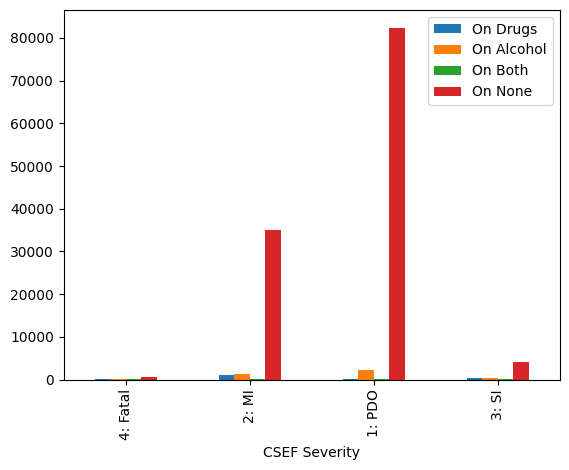

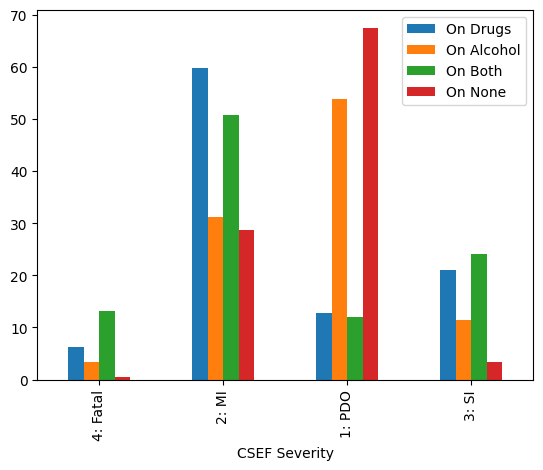

In [42]:
pd_df = all_df.toPandas()
pd_df_per = all_df_per.toPandas()

pd_df.plot(kind='bar', x='CSEF Severity')
plt.savefig('severe.png')
pd_df_per.plot(kind='bar', x='CSEF Severity')
plt.savefig('severe_per.png')

## 5. Mêmes requêtes avec RDD, DataFrame et Spark SQL

### 5.1 Date, heure, victimes, sexe, âge et permis du conducteur pour les accidents à Adélaïde

Amélioration 1. Dans le code d'origine, parseKey découpe chaque ligne avec split(','). Or certains champs du fichier des accidents contiennent une virgule entre guillemets (par exemple le nom de certaines communes) : la ligne est alors coupée en trop de morceaux et les colonnes sont décalées. On utilise donc le module `csv`, qui respecte les guillemets.

In [43]:
def parseKey(line):
    array_line = next(csv.reader([line]))
    return (array_line[0], array_line[1:])

units_rdd1 = units_rdd.map(parseKey)
crash_rdd1 = crash_rdd.map(parseKey)

# Vérification : chaque ligne doit avoir le même nombre de champs
print("Champs par ligne (units) :", units_rdd1.map(lambda x: len(x[1])).distinct().collect())
print("Champs par ligne (crash) :", crash_rdd1.map(lambda x: len(x[1])).distinct().collect())

Champs par ligne (units) : [17]
Champs par ligne (crash) : [32]


In [44]:
joined_rdd = units_rdd1.join(crash_rdd1)

def parseRecord1(line):
    if line[1][1][1] == 'ADELAIDE':
        array_line = []
        array_line.append(line[1][1][1])
        array_line.append(line[1][0][7])
        array_line.append(line[1][0][8])
        array_line.append(line[1][0][11])
        array_line.append(line[1][1][12])
        array_line.append(line[1][1][6])
        array_line.append(line[1][1][9] + "-" + line[1][1][10] + "-" + line[1][1][11])
        return (array_line)

pharsed_rdd = joined_rdd.map(parseRecord1)
filtered_pharsed_rdd = pharsed_rdd.filter(lambda x: x is not None)
filtered_pharsed_rdd.take(10)

[['ADELAIDE',
  '044',
  'SA',
  'Not Towing',
  '06:00 pm',
  '0',
  '2012-February-Wednesday'],
 ['ADELAIDE',
  '026',
  'UNKNOWN',
  'Not Towing',
  '06:00 pm',
  '0',
  '2012-February-Wednesday'],
 ['ADELAIDE',
  'XXX',
  'UNKNOWN',
  'Not Towing',
  '06:00 pm',
  '0',
  '2012-February-Wednesday'],
 ['ADELAIDE', '025', 'SA', 'Unknown', '08:00 pm', '0', '2012-June-Friday'],
 ['ADELAIDE', '024', '', '', '08:00 pm', '0', '2012-June-Friday'],
 ['ADELAIDE',
  '073',
  'SA',
  'Not Towing',
  '03:10 pm',
  '0',
  '2012-January-Monday'],
 ['ADELAIDE',
  '020',
  'SA',
  'Not Towing',
  '03:10 pm',
  '0',
  '2012-January-Monday'],
 ['ADELAIDE',
  '046',
  'SA',
  'Not Towing',
  '12:20 pm',
  '0',
  '2012-January-Thursday'],
 ['ADELAIDE', '024', '', '', '12:20 pm', '0', '2012-January-Thursday'],
 ['ADELAIDE',
  '046',
  'SA',
  'Not Towing',
  '08:15 am',
  '0',
  '2012-January-Saturday']]

In [45]:
joined_df = crash_df.join(units_df, crash_df.REPORT_ID == units_df.REPORT_ID, how='inner')
def find_date(d, m, y):
    return y + "-" + m + "-" + d

find_date_udf = udf(find_date)
joined_date_df = joined_df.withColumn('Date', find_date_udf('Day', 'Month', 'Year'))
joined_date_df = joined_date_df.filter(col("Suburb") == 'ADELAIDE')
joined_date_df.select('Date', 'Time', 'Total Cas', 'Sex', 'Age', 'Licence Type', 'Suburb').show(10)

+--------------------+--------+---------+------+---+--------------+--------+
|                Date|    Time|Total Cas|   Sex|Age|  Licence Type|  Suburb|
+--------------------+--------+---------+------+---+--------------+--------+
| 2012-January-Monday|08:45 am|        0|  Male|084|          Full|ADELAIDE|
| 2012-January-Monday|08:45 am|        0|  Male|040|          Full|ADELAIDE|
| 2012-January-Friday|05:45 pm|        0|  Male|047|          Full|ADELAIDE|
| 2012-January-Friday|05:45 pm|        0|  Male|XXX|          NULL|ADELAIDE|
| 2012-January-Friday|07:30 pm|        1|Female|018| Provisional 2|ADELAIDE|
| 2012-January-Friday|07:30 pm|        1|  Male|020|          Full|ADELAIDE|
|2012-January-Satu...|08:00 am|        0|Female|024|Provisional 1 |ADELAIDE|
|2012-January-Satu...|08:00 am|        0|  Male|025|          NULL|ADELAIDE|
|2012-January-Satu...|10:20 pm|        0|Female|020|Provisional 1 |ADELAIDE|
|2012-January-Satu...|10:20 pm|        0|  Male|033|          Full|ADELAIDE|

In [46]:
units_df.createOrReplaceTempView("units_table")
crash_df.createOrReplaceTempView("crash_table")
joined_table = spark.sql('''
  SELECT (Year || '-' || Month || '-' || Day) as Date, Time, `Total Cas`, Sex, Age, `Licence Type`, Suburb
  FROM units_table u JOIN crash_table c
  ON u.REPORT_ID = c.REPORT_ID
  where c.Suburb == 'ADELAIDE'
''')
joined_table.show(10)

+--------------------+--------+---------+------+---+--------------+--------+
|                Date|    Time|Total Cas|   Sex|Age|  Licence Type|  Suburb|
+--------------------+--------+---------+------+---+--------------+--------+
| 2012-January-Monday|08:45 am|        0|  Male|084|          Full|ADELAIDE|
| 2012-January-Monday|08:45 am|        0|  Male|040|          Full|ADELAIDE|
| 2012-January-Friday|05:45 pm|        0|  Male|047|          Full|ADELAIDE|
| 2012-January-Friday|05:45 pm|        0|  Male|XXX|          NULL|ADELAIDE|
| 2012-January-Friday|07:30 pm|        1|Female|018| Provisional 2|ADELAIDE|
| 2012-January-Friday|07:30 pm|        1|  Male|020|          Full|ADELAIDE|
|2012-January-Satu...|08:00 am|        0|Female|024|Provisional 1 |ADELAIDE|
|2012-January-Satu...|08:00 am|        0|  Male|025|          NULL|ADELAIDE|
|2012-January-Satu...|10:20 pm|        0|Female|020|Provisional 1 |ADELAIDE|
|2012-January-Satu...|10:20 pm|        0|  Male|033|          Full|ADELAIDE|

### 5.2 Nombre total de victimes par quartier lorsque le conducteur n'a pas de permis

**Amélioration 2.** Dans le code d'origine, les trois versions de cette requête n'appliquent pas les mêmes filtres : elles ne calculent donc pas la même chose, et aucune ne garde uniquement les conducteurs sans permis. Ici, les trois versions calculent exactement la même chose (somme de Total Cas pour les conducteurs Unlicenced, par quartier). On vérifie que leurs résultats sont identiques, puis on compare leurs temps d'exécution.

In [47]:

def rdd_version():
    joined_rdd = units_rdd1.join(crash_rdd1)
    result = (joined_rdd.filter(lambda x: x[1][0][10] == 'Unlicenced')
                        .map(lambda x: (x[1][1][1], int(x[1][1][5])))
                        .reduceByKey(lambda a, b: a + b))
    return dict(result.collect())


def df_version():
    joined_df = crash_df.join(units_df, crash_df.REPORT_ID == units_df.REPORT_ID, how='inner')
    result = (joined_df.filter(col('Licence Type') == 'Unlicenced')
                       .groupby('Suburb')
                       .agg(F.sum('Total Cas').alias('Total casualty')))
    return {row['Suburb']: row['Total casualty'] for row in result.collect()}


def sql_version():
    result = spark.sql('''
      SELECT Suburb, SUM(`Total Cas`) AS total
      FROM units_table u JOIN crash_table c
      ON u.REPORT_ID = c.REPORT_ID
      WHERE `Licence Type` = 'Unlicenced'
      GROUP BY Suburb
    ''')
    return {row['Suburb']: row['total'] for row in result.collect()}

res_rdd = rdd_version()
res_df = df_version()
res_sql = sql_version()

assert res_rdd == res_df == res_sql
print("Les trois versions donnent le même résultat :", len(res_rdd), "quartiers")
print("Victimes à Adélaïde :", res_rdd['ADELAIDE'])

Les trois versions donnent le même résultat : 752 quartiers
Victimes à Adélaïde : 43


   Interface  Temps moyen (s)
0        RDD         2.312611
1  DataFrame         0.385350
2  Spark SQL         0.346086


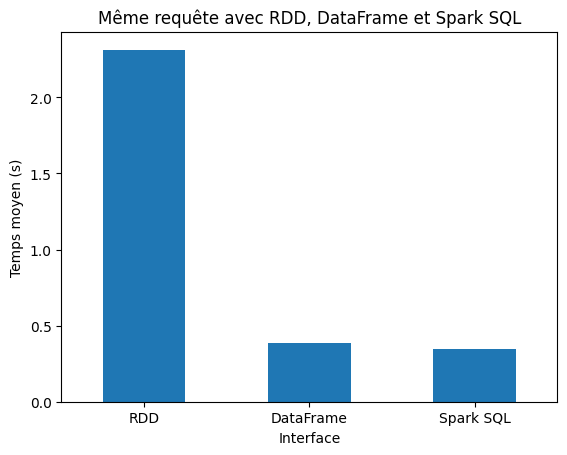

In [48]:

def chrono(fonction, repetitions=3):
    temps = []
    for _ in range(repetitions):
        debut = time.perf_counter()
        fonction()
        temps.append(time.perf_counter() - debut)
    return sum(temps) / len(temps)

temps_df = pd.DataFrame({
    "Interface": ["RDD", "DataFrame", "Spark SQL"],
    "Temps moyen (s)": [chrono(rdd_version), chrono(df_version), chrono(sql_version)],
})
print(temps_df)

temps_df.plot(kind='bar', x='Interface', y='Temps moyen (s)', legend=False)
plt.ylabel("Temps moyen (s)")
plt.title("Même requête avec RDD, DataFrame et Spark SQL")
plt.xticks(rotation=0)
plt.savefig('comparaison_interfaces.png')
plt.show()

## 6. Analyse

**Conducteurs.** L'âge moyen des conducteurs impliqués est presque identique pour les hommes (40,8 ans) et les femmes (40,1 ans). Environ 80 % des véhicules (218 366 sur 272 591) sont immatriculés en Australie-Méridionale, ce qui est logique pour des données de cet État.

**Types d'accidents.** Les collisions avec un obstacle fixe sont les plus mortelles (245 décès), devant les chocs frontaux (136) et les piétons renversés (109). Les accidents par l'arrière, pourtant fréquents, causent peu de décès (33).

**Alcool et drogues.** Sans alcool ni drogues, 67 % des accidents ne font que des dégâts matériels et seulement 0,4 % sont mortels. Ce taux monte à 3,4 % avec l'alcool, 6,3 % avec les drogues et 13,1 % avec les deux : la gravité augmente nettement, surtout quand les deux sont combinés.

**Lecture des CSV (amélioration 1).** Avec split(','), certaines lignes du fichier des accidents étaient coupées en plus de 32 champs, car des noms de commune contiennent une virgule. Les colonnes étaient alors décalées. Avec le module csv, toutes les lignes ont le bon nombre de champs.

**RDD, DataFrame et Spark SQL (amélioration 2).** Sur la même requête, les trois interfaces donnent exactement le même résultat (752 quartiers, 43 victimes à Adélaïde). Les DataFrames (0,39 s) et Spark SQL (0,35 s) ont des temps très proches, car ils passent par le même optimiseur de Spark (Catalyst). Les RDD sont environ **6 fois plus lents** (2,31 s), car les fonctions Python (lambda) sont exécutées hors de la JVM et ne peuvent pas être optimisées par Spark.

**Limites.** Les données (environ 77 Mo) tiennent sur une seule machine, et Spark tourne ici en mode local. Les temps mesurés dépendent de la machine et du nombre de cœurs.

## 7. Conclusion

Cette étude a reproduit l'analyse des accidents de la route en Australie-Méridionale (2012-2019), soit 127 672 accidents et 272 591 véhicules, avec les trois interfaces de PySpark.

- Les accidents les plus mortels sont les collisions avec un obstacle fixe et les chocs frontaux.
- L'alcool et surtout les drogues augmentent fortement la gravité : un accident est environ 30 fois plus souvent mortel quand les deux sont présents.
- Le découpage des lignes avec split(',') peut fausser les résultats : il faut utiliser un lecteur CSV qui respecte les guillemets.
- Les DataFrames et Spark SQL sont plus simples à écrire et environ 6 fois plus rapides que les RDD.

En pratique, on privilégie donc les DataFrames ou Spark SQL pour l'analyse de données, et on réserve les RDD aux traitements que ces interfaces ne permettent pas, comme le partitionnement personnalisé. Le même code pourrait s'exécuter sans modification sur un cluster, pour des volumes beaucoup plus importants.